# 03 — Results: which model is best?

All numbers come from `results/<model>_seed<seed>/` (6 models × seeds 42, 43, 44, trained on one Tesla T4 with identical
settings). The tables and figures are produced by `pneumonia/compare.py` — the same code as
`python scripts/compare_results.py`.

**How to read the numbers.** The primary metric is the **test ROC-AUC**: it measures how well a model separates sick from
healthy children regardless of where the decision threshold is put, and it barely changes between seeds. Accuracy,
recall, specificity, precision and F1 use the fixed threshold 0.5; they depend strongly on where each training run
happens to place its probabilities and vary much more between seeds. Tuning the threshold on the validation set is left
as future work (team decision, see `docs/Plan.md`).

In [1]:
import sys
from pathlib import Path

REPO_ROOT = Path.cwd() if (Path.cwd() / "pneumonia").is_dir() else Path.cwd().parent
sys.path.insert(0, str(REPO_ROOT))

from IPython.display import Image, Markdown, display

from pneumonia.compare import build_report, collect_runs, summary_markdown

RESULTS_DIR = REPO_ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
summary = build_report(RESULTS_DIR, FIGURES_DIR)
runs = collect_runs(RESULTS_DIR)
print(f"{len(runs)} runs, {runs['model'].nunique()} models, seeds {sorted(runs['seed'].unique())}")

C:\Users\uid\Documents\VGTU\NeuralNetworks\Course project\pneumonia_image_classification\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


18 runs, 6 models, seeds [np.int64(42), np.int64(43), np.int64(44)]


## 1. Comparison table (test set, mean ± std over 3 seeds)

In [2]:
display(Markdown(summary_markdown(summary)))

| Model | Params (M) | Seeds | ROC-AUC | Accuracy | Recall (sensitivity) | Specificity | Precision | F1 | Train (min) | ms / image |
|---|---|---|---|---|---|---|---|---|---|---|
| Baseline CNN | 0.4 | 3 | 0.935 ± 0.008 | 0.810 ± 0.125 | 0.979 ± 0.019 | 0.530 ± 0.364 | 0.791 ± 0.121 | 0.871 ± 0.071 | 3.3 ± 0.6 | 1.0 ± 0.1 |
| VGG16 | 134.3 | 3 | 0.978 ± 0.008 | 0.914 ± 0.017 | 0.980 ± 0.020 | 0.803 ± 0.060 | 0.893 ± 0.027 | 0.935 ± 0.012 | 10.5 ± 3.2 | 9.7 ± 0.1 |
| ResNet50 | 23.5 | 3 | 0.978 ± 0.001 | 0.904 ± 0.048 | 0.985 ± 0.009 | 0.768 ± 0.142 | 0.880 ± 0.063 | 0.929 ± 0.032 | 5.3 ± 1.9 | 8.4 ± 0.1 |
| DenseNet121 | 7.0 | 3 | 0.978 ± 0.002 | 0.900 ± 0.027 | 0.991 ± 0.001 | 0.746 ± 0.070 | 0.868 ± 0.031 | 0.925 ± 0.019 | 6.3 ± 1.3 | 24.5 ± 0.7 |
| EfficientNet-B0 | 4.0 | 3 | 0.971 ± 0.002 | 0.884 ± 0.006 | 0.994 ± 0.006 | 0.701 ± 0.026 | 0.847 ± 0.011 | 0.915 ± 0.004 | 5.5 ± 1.2 | 13.1 ± 0.2 |
| MobileNetV3-L | 4.2 | 3 | 0.975 ± 0.004 | 0.905 ± 0.009 | 0.983 ± 0.012 | 0.775 ± 0.039 | 0.880 ± 0.017 | 0.928 ± 0.006 | 3.3 ± 1.0 | 10.3 ± 0.7 |


## 2. Metrics per model

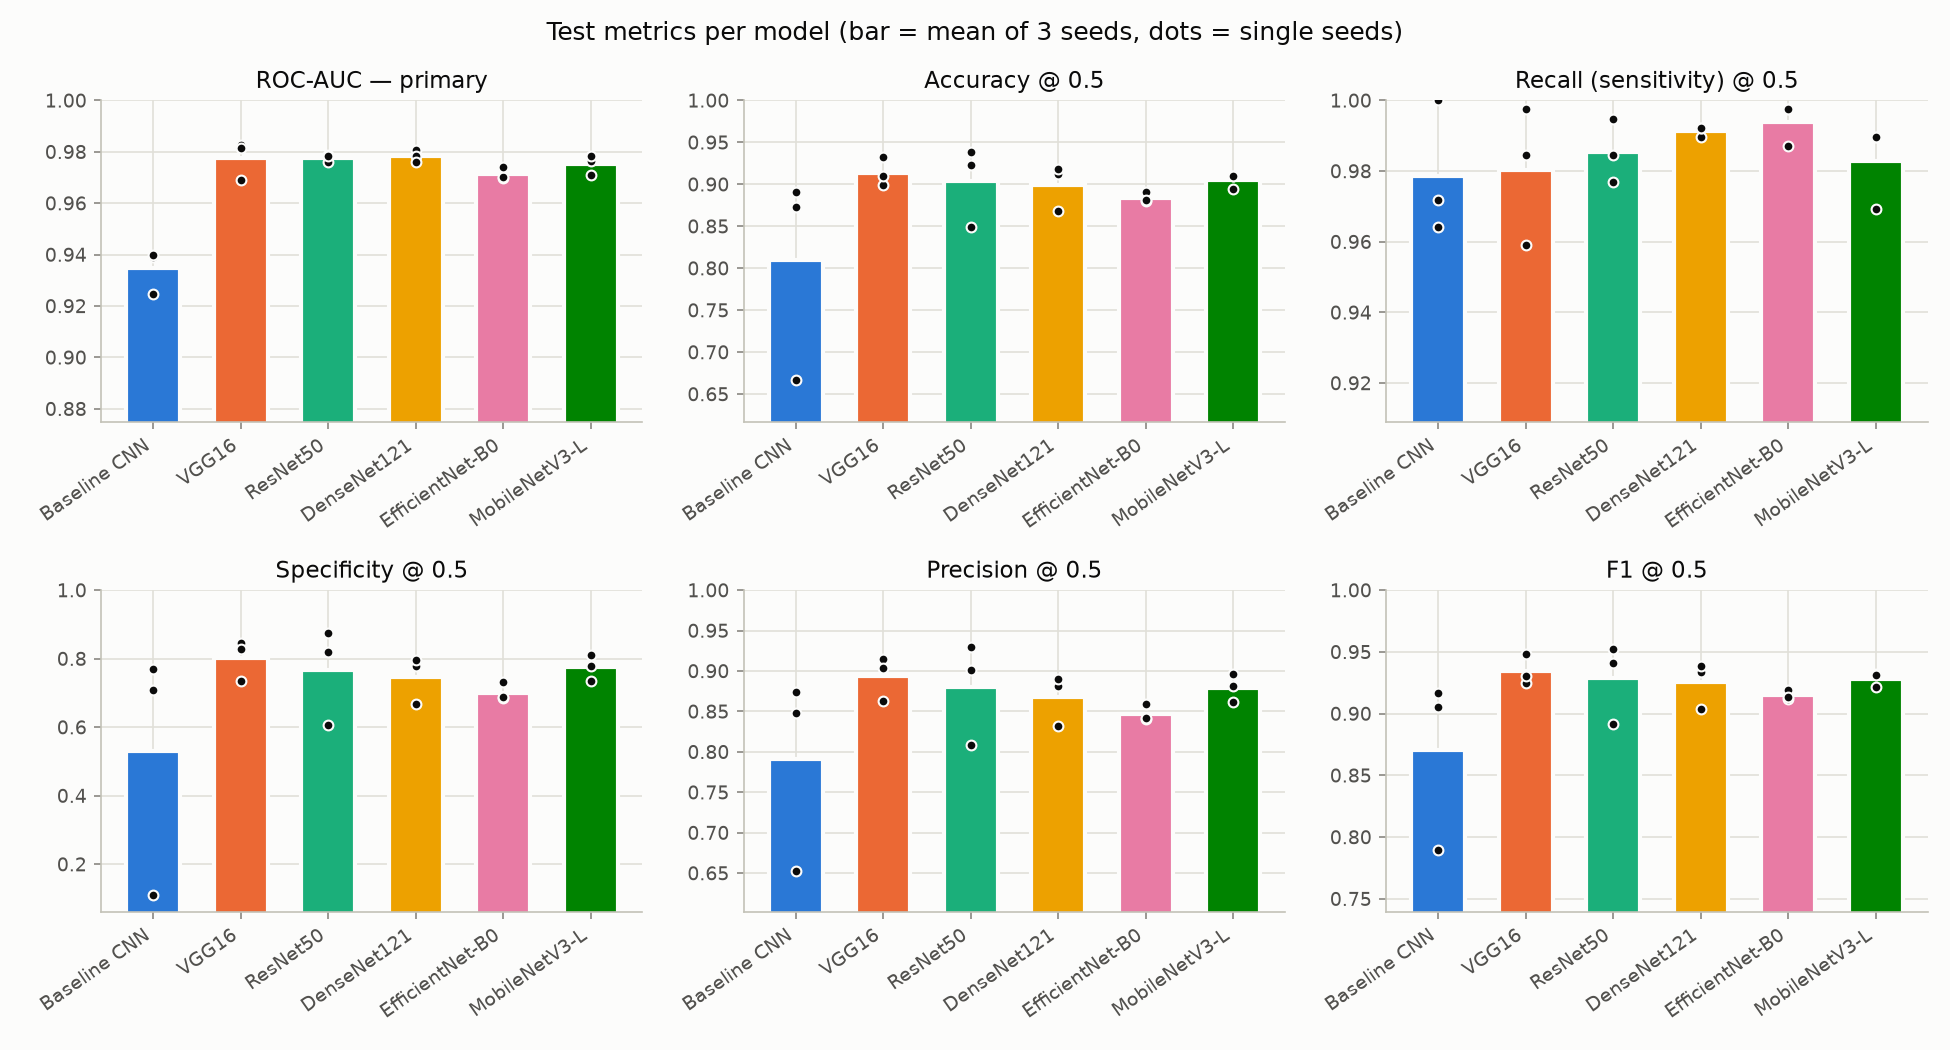

In [3]:
Image(FIGURES_DIR / 'comparison_metrics.png')

- All five ImageNet-pretrained models beat the from-scratch baseline clearly on ROC-AUC (≈0.97–0.98 vs 0.935).
- Among the pretrained models the differences in ROC-AUC (0.971–0.978) are about as large as the seed-to-seed spread —
  VGG16, ResNet50 and DenseNet121 are effectively tied.
- Recall is high for every model (≥ 0.98): almost no sick child is missed. The weak spot is **specificity** — at the
  0.5 threshold many healthy children are called sick, and this number jumps between seeds (baseline 0.11–0.77).

## 3. ROC curves

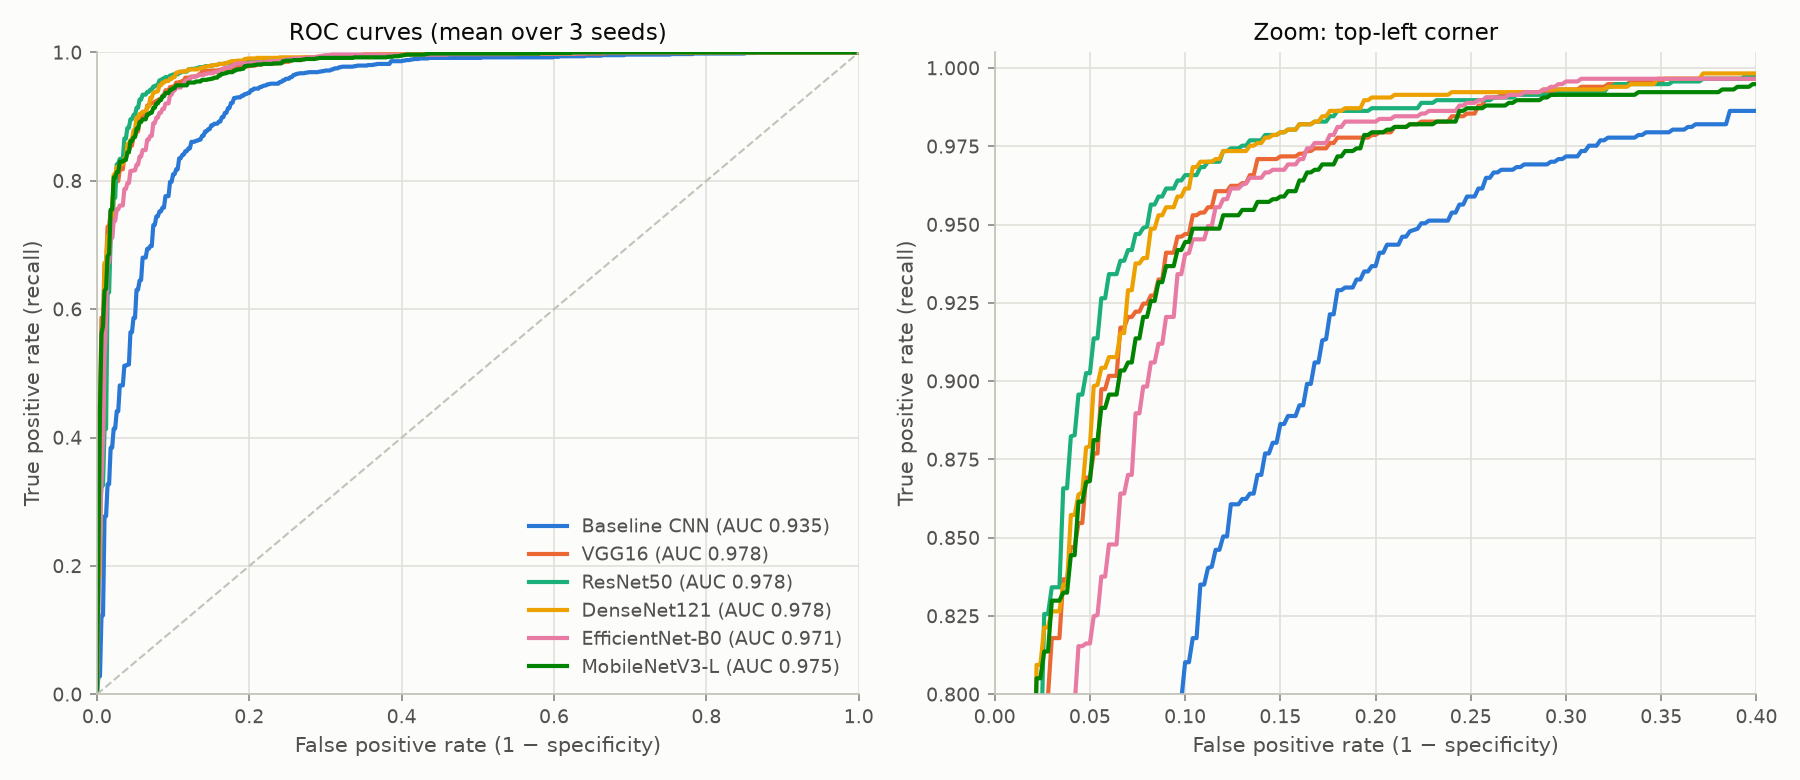

In [4]:
Image(FIGURES_DIR / 'comparison_roc.png')

The curves of the pretrained models lie almost on top of each other; the baseline is visibly lower. Every model could
reach a much better specificity at a small cost in recall by moving the threshold — that is what the curve shows.

## 4. Training curves

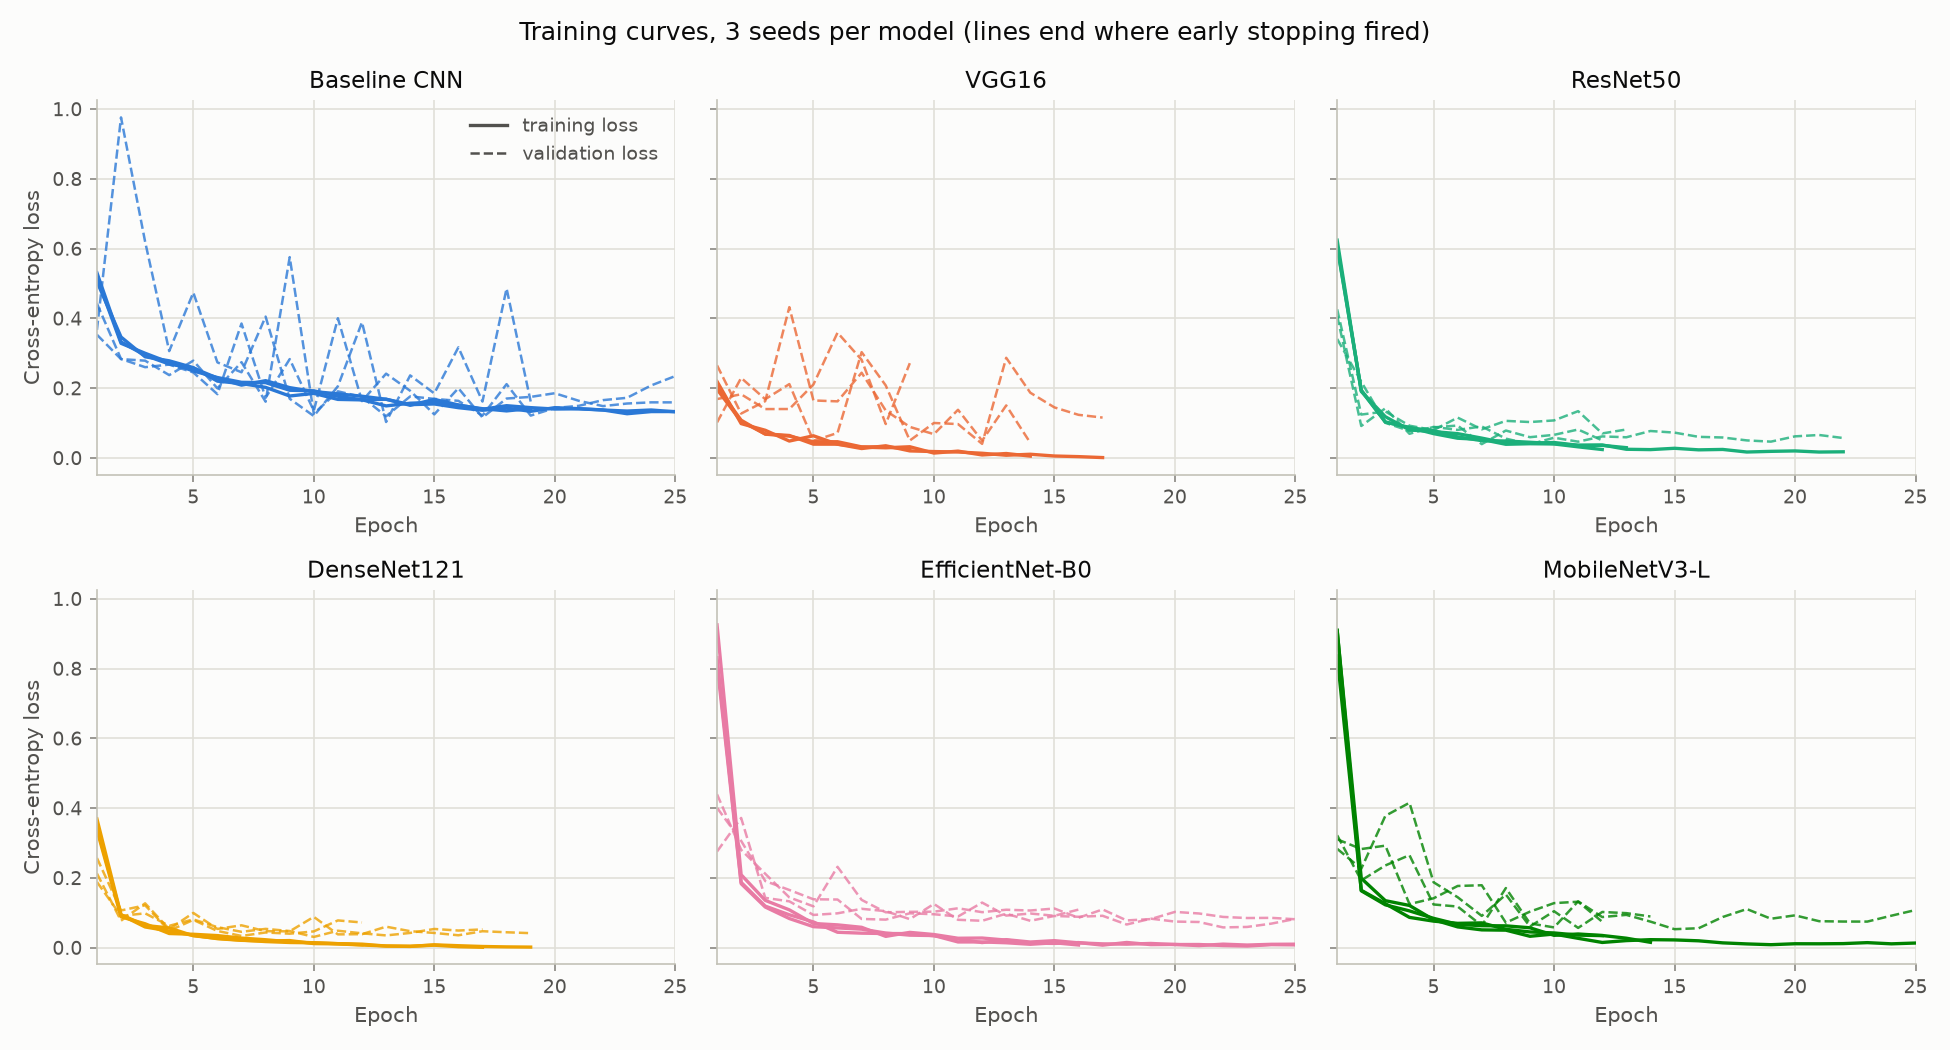

In [5]:
Image(FIGURES_DIR / 'comparison_training_curves.png')

Pretrained models reach their best validation score within a few epochs and then over-fit (training loss → 0).
The validation loss of the baseline and of VGG16 jumps a lot between epochs, although the validation ROC-AUC stays
smooth: the ranking is stable, the probability scale is not.

## 5. Confusion matrices

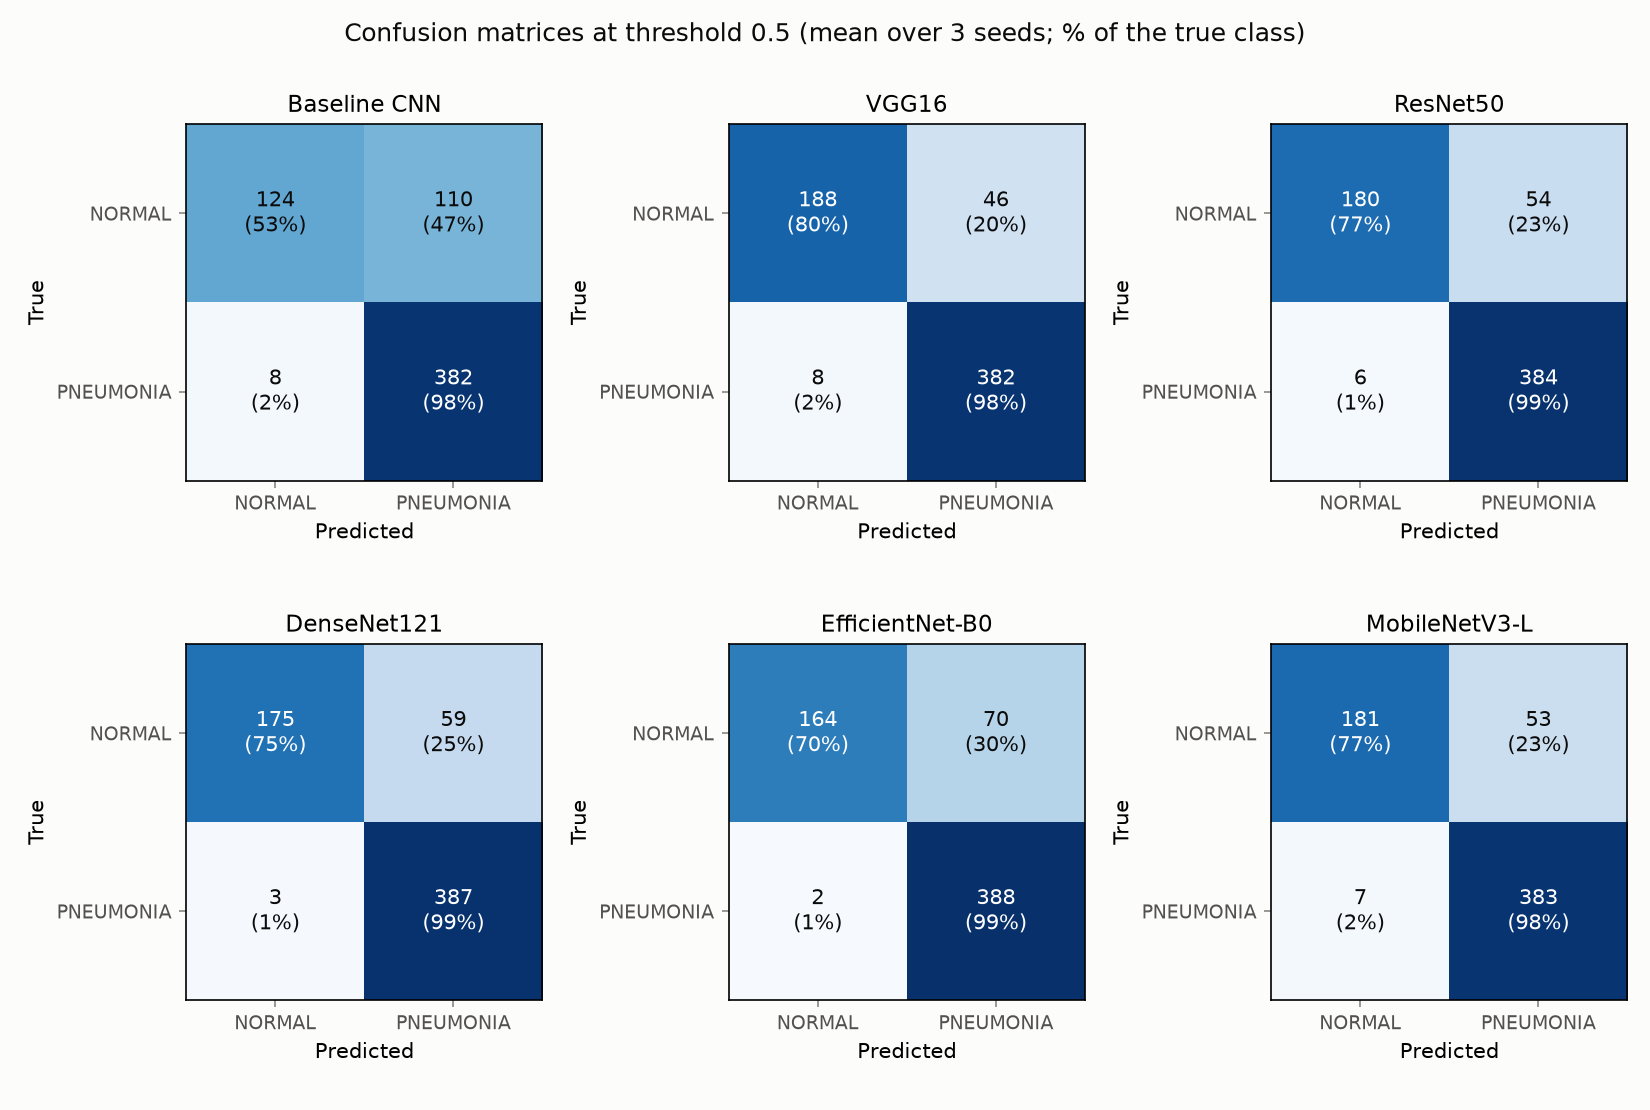

In [6]:
Image(FIGURES_DIR / 'comparison_confusion_matrices.png')

## 6. Quality vs speed and size

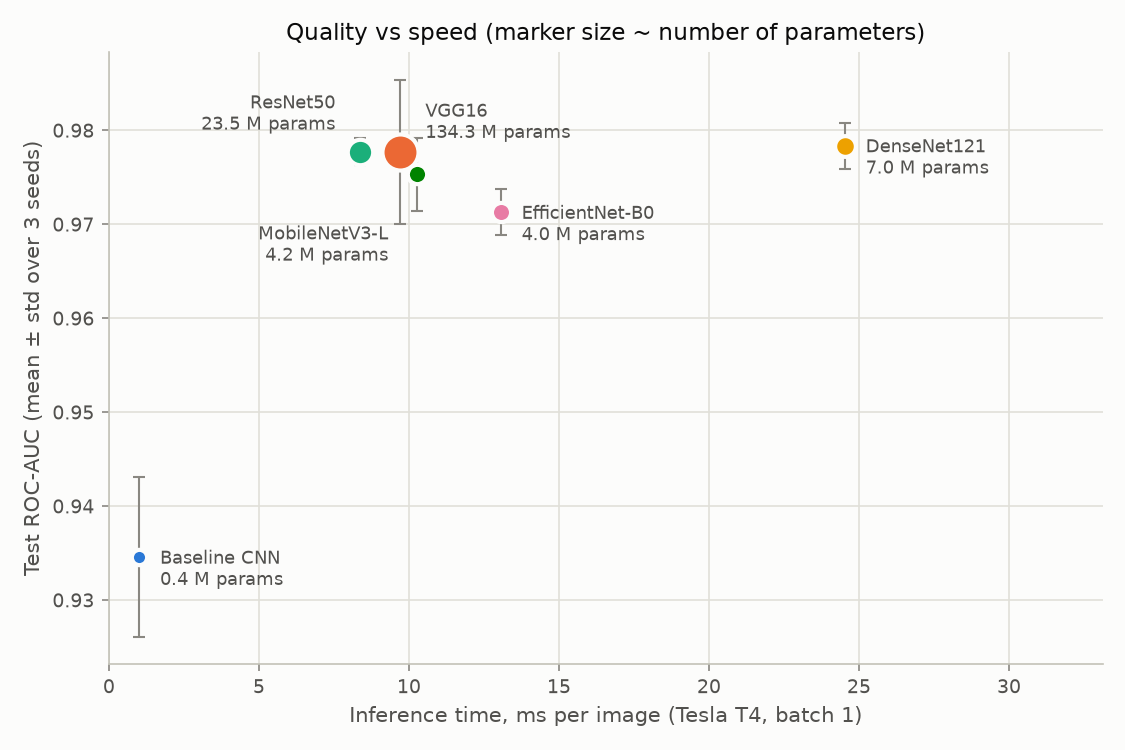

In [7]:
Image(FIGURES_DIR / 'comparison_efficiency.png')

- **MobileNetV3-Large** is the best trade-off: ROC-AUC close to the top, the shortest training of the pretrained models
  and ~10 ms per image with only 4.2 M parameters.
- **VGG16** has the best threshold-0.5 metrics on average but is 32× larger than MobileNetV3 and trains 3× longer.
- **DenseNet121** is the slowest at inference (~25 ms) despite having only 7 M parameters — parameter count is not a good
  proxy for speed.

Grad-CAM pictures of every run are in `results/<run>/gradcam.jpg`; the cross-model comparison is task ID-17.